In [1]:
import json 
from pathlib import Path 
import pandas as pd 
import requests

BASE_URL = "https://raw.githubusercontent.com/statsbomb/open-data/master/data"
RAW_DIR = Path("../data/raw")
RAW_DIR.mkdir(parents=True, exist_ok=True)
RAW_DIR.mkdir(parents=True , exist_ok=True)

In [2]:
r = requests.get(f"{BASE_URL}/competitions.json", timeout=30)
r.raise_for_status()
competitions = pd.DataFrame(r.json())

competitions[(competitions.competition_id == 7) & (competitions.season_id == 27)]

,competition_id,season_id,country_name,competition_name,competition_gender,competition_youth,competition_international,season_name,match_updated,match_updated_360,match_available_360,match_available
63,7,27,France,Ligue 1,male,False,False,2015/2016,2026-05-12T22:46:54.722768,NaN,NaN,2026-05-12T22:46:54.722768


In [4]:
url = f"{BASE_URL}/matches/7/27.json"
matches_raw = requests.get(url, timeout=30).json()

with open(RAW_DIR / "matches_7_27.json", "w", encoding="utf-8") as f:
    json.dump(matches_raw, f, ensure_ascii=False)

print(len(matches_raw), "matchs")   # attendu : 377

377 matchs


In [5]:
print(json.dumps(matches_raw[0], indent=2, ensure_ascii=False)[:2000])

{
  "match_id": 3901259,
  "match_date": "2016-05-14",
  "kick_off": "19:00:00.000",
  "competition": {
    "competition_id": 7,
    "country_name": "France",
    "competition_name": "Ligue 1"
  },
  "season": {
    "season_id": 27,
    "season_name": "2015/2016"
  },
  "home_team": {
    "home_team_id": 133,
    "home_team_name": "Troyes",
    "home_team_gender": "male",
    "home_team_group": null,
    "country": {
      "id": 78,
      "name": "France"
    },
    "managers": [
      {
        "id": 1003442,
        "name": "Mohamed Bradja",
        "nickname": null,
        "dob": "1969-11-16",
        "country": {
          "id": 4,
          "name": "Algeria"
        }
      }
    ]
  },
  "away_team": {
    "away_team_id": 147,
    "away_team_name": "Olympique de Marseille",
    "away_team_gender": "male",
    "away_team_group": null,
    "country": {
      "id": 78,
      "name": "France"
    },
    "managers": [
      {
        "id": 3004,
        "name": "Franck Passi",
      

In [6]:
matches = pd.json_normalize(matches_raw)
matches.columns.tolist()
matches[["match_id", "match_date", "home_team.home_team_name",
         "away_team.away_team_name", "home_score", "away_score"]].head()

,match_id,match_date,home_team.home_team_name,away_team.away_team_name,home_score,away_score
0,3901259,2016-05-14,Troyes,Olympique de Marseille,1,1
1,3900533,2015-12-02,AS Monaco,Stade Malherbe Caen,1,1
2,3900528,2015-11-29,Bordeaux,Stade Malherbe Caen,1,4
3,3900629,2016-02-07,Olympique de Marseille,Paris Saint-Germain,1,2
4,3829509,2015-10-18,Olympique de Marseille,Lorient,1,1


In [7]:
(RAW_DIR / "events").mkdir(exist_ok=True)

def download_events(match_id):
    path = RAW_DIR / "events" / f"{match_id}.json"
    if path.exists():
        return json.loads(path.read_text(encoding="utf-8"))
    data = requests.get(f"{BASE_URL}/events/{match_id}.json", timeout=30).json()
    path.write_text(json.dumps(data, ensure_ascii=False), encoding="utf-8")
    return data

sample_ids = matches["match_id"].head(3).tolist()
events_by_match = {mid: download_events(mid) for mid in sample_ids}

for mid, ev in events_by_match.items():
    print(mid, len(ev), "événements")

3901259 4188 événements
3900533 3681 événements
3900528 3490 événements


In [8]:
events_raw = events_by_match[sample_ids[0]]
print(json.dumps(events_raw[0], indent=2, ensure_ascii=False))

{
  "id": "8bd86862-16e4-435e-8615-a1872ef82d94",
  "index": 1,
  "period": 1,
  "timestamp": "00:00:00.000",
  "minute": 0,
  "second": 0,
  "type": {
    "id": 35,
    "name": "Starting XI"
  },
  "possession": 1,
  "possession_team": {
    "id": 133,
    "name": "Troyes"
  },
  "play_pattern": {
    "id": 1,
    "name": "Regular Play"
  },
  "team": {
    "id": 133,
    "name": "Troyes"
  },
  "duration": 0.0,
  "tactics": {
    "formation": 4141,
    "lineup": [
      {
        "player": {
          "id": 36553,
          "name": "Matthieu Dreyer"
        },
        "position": {
          "id": 1,
          "name": "Goalkeeper"
        },
        "jersey_number": 1
      },
      {
        "player": {
          "id": 7301,
          "name": "Lossémy Karaboué"
        },
        "position": {
          "id": 2,
          "name": "Right Back"
        },
        "jersey_number": 24
      },
      {
        "player": {
          "id": 31625,
          "name": "Johan Martial"
        }

In [9]:
events_raw = events_by_match[sample_ids[0]]
print(json.dumps(events_raw[0], indent=2, ensure_ascii=False))

{
  "id": "8bd86862-16e4-435e-8615-a1872ef82d94",
  "index": 1,
  "period": 1,
  "timestamp": "00:00:00.000",
  "minute": 0,
  "second": 0,
  "type": {
    "id": 35,
    "name": "Starting XI"
  },
  "possession": 1,
  "possession_team": {
    "id": 133,
    "name": "Troyes"
  },
  "play_pattern": {
    "id": 1,
    "name": "Regular Play"
  },
  "team": {
    "id": 133,
    "name": "Troyes"
  },
  "duration": 0.0,
  "tactics": {
    "formation": 4141,
    "lineup": [
      {
        "player": {
          "id": 36553,
          "name": "Matthieu Dreyer"
        },
        "position": {
          "id": 1,
          "name": "Goalkeeper"
        },
        "jersey_number": 1
      },
      {
        "player": {
          "id": 7301,
          "name": "Lossémy Karaboué"
        },
        "position": {
          "id": 2,
          "name": "Right Back"
        },
        "jersey_number": 24
      },
      {
        "player": {
          "id": 31625,
          "name": "Johan Martial"
        }

In [10]:
events = pd.json_normalize(events_raw)
events.columns.tolist()

['id',
 'index',
 'period',
 'timestamp',
 'minute',
 'second',
 'possession',
 'duration',
 'type.id',
 'type.name',
 'possession_team.id',
 'possession_team.name',
 'play_pattern.id',
 'play_pattern.name',
 'team.id',
 'team.name',
 'tactics.formation',
 'tactics.lineup',
 'related_events',
 'off_camera',
 'location',
 'player.id',
 'player.name',
 'position.id',
 'position.name',
 'pass.recipient.id',
 'pass.recipient.name',
 'pass.length',
 'pass.angle',
 'pass.height.id',
 'pass.height.name',
 'pass.end_location',
 'pass.body_part.id',
 'pass.body_part.name',
 'pass.type.id',
 'pass.type.name',
 'carry.end_location',
 'under_pressure',
 'dribble.outcome.id',
 'dribble.outcome.name',
 'duel.type.id',
 'duel.type.name',
 'duel.outcome.id',
 'duel.outcome.name',
 'counterpress',
 'pass.outcome.id',
 'pass.outcome.name',
 'ball_receipt.outcome.id',
 'ball_receipt.outcome.name',
 'foul_won.defensive',
 'pass.cross',
 'out',
 'clearance.aerial_won',
 'clearance.head',
 'clearance.body_p

In [11]:
shots = events[events["type.name"] == "Shot"].copy()
print(len(shots), "tirs")

shot_cols = [c for c in shots.columns if c.startswith("shot.")]
shot_cols

27 tirs


['shot.statsbomb_xg',
 'shot.end_location',
 'shot.key_pass_id',
 'shot.body_part.id',
 'shot.body_part.name',
 'shot.type.id',
 'shot.type.name',
 'shot.outcome.id',
 'shot.outcome.name',
 'shot.technique.id',
 'shot.technique.name',
 'shot.freeze_frame',
 'shot.one_on_one',
 'shot.open_goal',
 'shot.first_time',
 'shot.aerial_won']

In [12]:
shots[["x", "y"]] = pd.DataFrame(shots["location"].tolist(), index=shots.index)

cols = ["match_id" if "match_id" in shots.columns else "id",
        "team.name", "player.name", "minute", "x", "y",
        "shot.body_part.name", "shot.type.name",
        "shot.technique.name", "shot.outcome.name", "shot.statsbomb_xg"]
shots[cols].head(10)

,id,team.name,player.name,minute,x,y,shot.body_part.name,shot.type.name,shot.technique.name,shot.outcome.name,shot.statsbomb_xg
299,120a43f8-aa90-4bc8-b182-ec9033c0b764,Olympique de Marseille,Romain Alessandrini,5,106.0,26.5,Left Foot,Open Play,Normal,Off T,0.039658
382,57108d42-6921-4e92-8bc0-0def5245f550,Olympique de Marseille,Steven Fletcher,7,108.0,27.2,Left Foot,Open Play,Normal,Off T,0.120848
407,50f18edf-8dab-49df-b5ab-4ad96cef6cb6,Olympique de Marseille,Rémy Cabella,8,102.1,32.6,Right Foot,Open Play,Normal,Blocked,0.087109
450,33efe5ac-92e2-4f84-9a8a-838a4dff13a7,Troyes,Fabien Camus,9,103.4,47.5,Right Foot,Open Play,Normal,Goal,0.489421
700,a0bc5189-9213-4fdb-a49e-394321e98082,Olympique de Marseille,Romain Alessandrini,14,97.1,26.8,Right Foot,Open Play,Normal,Blocked,0.017896
921,e192257f-7c23-4e75-86cc-b3765b796564,Olympique de Marseille,Florian Thauvin,19,118.2,44.1,Right Foot,Open Play,Half Volley,Post,0.594122
1009,cc831166-388c-4668-9de6-f523cad6292e,Olympique de Marseille,Rémy Cabella,21,92.0,31.3,Right Foot,Open Play,Normal,Off T,0.031144
1039,a21f59ca-f58a-4c04-ad78-fb0609241b52,Troyes,Fabien Camus,23,111.7,19.2,Right Foot,Open Play,Normal,Wayward,0.008972
1488,f3655162-dd59-4198-a7f4-154ad7603e8f,Troyes,Chaouki Ben Saada,35,99.0,51.4,Left Foot,Open Play,Normal,Off T,0.044663
1577,27e5ea63-261d-4dcb-945c-fff9ef828d10,Olympique de Marseille,Romain Alessandrini,36,101.8,22.6,Left Foot,Open Play,Normal,Blocked,0.019081


In [13]:
shots[["x", "y"]] = pd.DataFrame(shots["location"].tolist(), index=shots.index)

cols = ["match_id" if "match_id" in shots.columns else "id",
        "team.name", "player.name", "minute", "x", "y",
        "shot.body_part.name", "shot.type.name",
        "shot.technique.name", "shot.outcome.name", "shot.statsbomb_xg"]
shots[cols].head(10)

,id,team.name,player.name,minute,x,y,shot.body_part.name,shot.type.name,shot.technique.name,shot.outcome.name,shot.statsbomb_xg
299,120a43f8-aa90-4bc8-b182-ec9033c0b764,Olympique de Marseille,Romain Alessandrini,5,106.0,26.5,Left Foot,Open Play,Normal,Off T,0.039658
382,57108d42-6921-4e92-8bc0-0def5245f550,Olympique de Marseille,Steven Fletcher,7,108.0,27.2,Left Foot,Open Play,Normal,Off T,0.120848
407,50f18edf-8dab-49df-b5ab-4ad96cef6cb6,Olympique de Marseille,Rémy Cabella,8,102.1,32.6,Right Foot,Open Play,Normal,Blocked,0.087109
450,33efe5ac-92e2-4f84-9a8a-838a4dff13a7,Troyes,Fabien Camus,9,103.4,47.5,Right Foot,Open Play,Normal,Goal,0.489421
700,a0bc5189-9213-4fdb-a49e-394321e98082,Olympique de Marseille,Romain Alessandrini,14,97.1,26.8,Right Foot,Open Play,Normal,Blocked,0.017896
921,e192257f-7c23-4e75-86cc-b3765b796564,Olympique de Marseille,Florian Thauvin,19,118.2,44.1,Right Foot,Open Play,Half Volley,Post,0.594122
1009,cc831166-388c-4668-9de6-f523cad6292e,Olympique de Marseille,Rémy Cabella,21,92.0,31.3,Right Foot,Open Play,Normal,Off T,0.031144
1039,a21f59ca-f58a-4c04-ad78-fb0609241b52,Troyes,Fabien Camus,23,111.7,19.2,Right Foot,Open Play,Normal,Wayward,0.008972
1488,f3655162-dd59-4198-a7f4-154ad7603e8f,Troyes,Chaouki Ben Saada,35,99.0,51.4,Left Foot,Open Play,Normal,Off T,0.044663
1577,27e5ea63-261d-4dcb-945c-fff9ef828d10,Olympique de Marseille,Romain Alessandrini,36,101.8,22.6,Left Foot,Open Play,Normal,Blocked,0.019081


In [14]:
shots["match_id"] = sample_ids[0]

In [15]:
shots["shot.outcome.name"].value_counts()   # Goal, Saved, Off T, Blocked...
shots["shot.body_part.name"].value_counts() # Right Foot, Left Foot, Head
shots["shot.type.name"].value_counts()      # Open Play, Free Kick, Penalty, Corner
shots[["x", "y"]].describe()                # x entre 0 et 120, y entre 0 et 80

,x,y
count,27.000000,27.000000
mean,103.025926,40.518519
std,7.239666,10.592125
min,90.900000,19.200000
25%,97.750000,31.950000
50%,102.900000,43.600000
75%,107.600000,47.850000
max,118.200000,56.000000


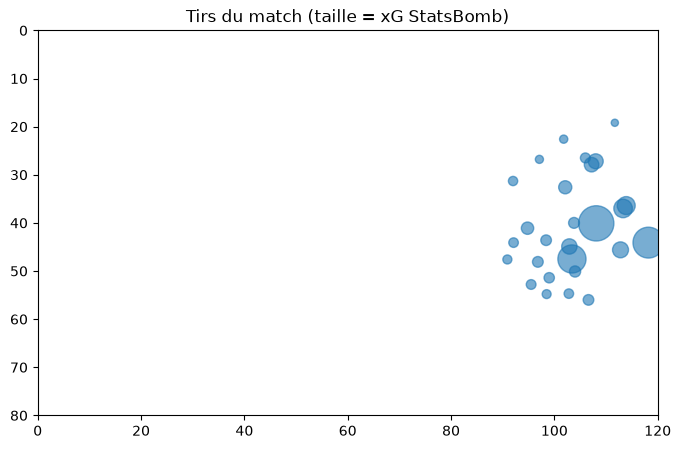

In [17]:
import matplotlib.pyplot as plt   # pip install matplotlib si besoin

plt.figure(figsize=(8, 5))
plt.scatter(shots["x"], shots["y"], s=shots["shot.statsbomb_xg"] * 800 + 20, alpha=0.6)
plt.xlim(0, 120); plt.ylim(80, 0)
plt.title("Tirs du match (taille = xG StatsBomb)")
plt.show()